# 03 · Modelo y evaluación

**Objetivo:** entrenar un modelo que puntúe el **riesgo** de cada celda para el año siguiente, medir si sirve y dibujar las celdas más prioritarias.

Usamos un **Random Forest** (muchos árboles de decisión que votan). Es simple, no necesita normalizar datos y deja ver qué variables importan.

Para saber si el modelo aporta algo, lo comparamos con dos referencias:
- **Aleatorio:** acertar al azar (equivale a la proporción de alertas).
- **Persistencia:** "si ya perdió bosque el último año, volverá a perder".

In [1]:
import json
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, precision_score, recall_score

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

ZONA = "guaviare"
PROCESSED = RAIZ / "data" / "processed"
SEMILLA = 42   # fija el azar para que los resultados se puedan repetir

panel = pd.read_csv(PROCESSED / f"panel_{ZONA}.csv")
meta_celdas = json.loads((PROCESSED / f"meta_celdas_{ZONA}.json").read_text())
UMBRAL_HA = meta_celdas["umbral_ha"]

FEATURES = [
    "pct_bosque_2000",
    "pct_bosque_restante",
    "perdida_acum_pct",
    "perdida_ha_ultimo",
    "perdida_ha_ult3",
    "perdida_vecinas_ha_ultimo",
    "perdida_vecinas_ha_ult3",
]
print(f"{len(panel):,} filas | alerta = pérdida >= {UMBRAL_HA} ha al año siguiente")

258,732 filas | alerta = pérdida >= 2.0 ha al año siguiente


## 1. Separar los conjuntos

La columna `conjunto` ya viene del notebook 02 (división por tiempo).

In [2]:
train = panel[panel["conjunto"] == "train"]
val = panel[panel["conjunto"] == "val"]
test = panel[panel["conjunto"] == "test"]

for nombre, df in [("train", train), ("val", val), ("test", test)]:
    print(f"{nombre}: {len(df):,} filas, {df['alerta'].mean() * 100:.2f}% con alerta")

if min(train["alerta"].sum(), val["alerta"].sum(), test["alerta"].sum()) == 0:
    raise ValueError("Algún conjunto no tiene alertas. Baja UMBRAL_HA en el notebook 02 y vuelve a ejecutarlo.")

train: 209,457 filas, 10.09% con alerta
val: 24,639 filas, 9.87% con alerta
test: 24,636 filas, 6.42% con alerta


## 2. Entrenar

`class_weight="balanced_subsample"` le da más peso a las alertas, que son pocas. `random_state` fija el azar.

In [3]:
modelo = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=20,
    class_weight="balanced_subsample",
    random_state=SEMILLA,
    n_jobs=-1,
)
modelo.fit(train[FEATURES], train["alerta"])

score_val = modelo.predict_proba(val[FEATURES])[:, 1]
score_test = modelo.predict_proba(test[FEATURES])[:, 1]
print("Modelo entrenado")

Modelo entrenado


## 3. Elegir el umbral de decisión (solo con validación)

El modelo da una probabilidad de riesgo. Para convertirla en "alerta sí/no" hay que escoger un corte. Lo elegimos en **validación** (el punto con mejor equilibrio entre precisión y recall) y **nunca** mirando `test`, que es el examen final.

In [4]:
p, r, u = precision_recall_curve(val["alerta"], score_val)
f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
UMBRAL_RIESGO = float(u[np.argmax(f1)])
print(f"Umbral de riesgo elegido en validación: {UMBRAL_RIESGO:.3f}")

Umbral de riesgo elegido en validación: 0.805


## 4. Evaluar

Tres métricas:
- **PR-AUC:** resumen general cuando hay pocas alertas (más alto es mejor; el azar da la tasa de alertas).
- **Precisión:** de las celdas marcadas, ¿qué fracción era alerta real?
- **Recall:** de las alertas reales, ¿qué fracción detectamos?

In [5]:
def metricas(y, score, umbral):
    pred = (score >= umbral).astype(int)
    return {
        "PR-AUC": average_precision_score(y, score),
        "precisión": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
    }


resultados = []
for conjunto, df, s_rf in [("validación", val, score_val), ("prueba", test, score_test)]:
    y = df["alerta"].values
    resultados.append({"conjunto": conjunto, "modelo": "Aleatorio", "PR-AUC": y.mean(), "precisión": np.nan, "recall": np.nan})
    resultados.append({"conjunto": conjunto, "modelo": "Persistencia", **metricas(y, df["perdida_ha_ultimo"].values, UMBRAL_HA)})
    resultados.append({"conjunto": conjunto, "modelo": "Random Forest", **metricas(y, s_rf, UMBRAL_RIESGO)})

pd.DataFrame(resultados).round(3)

,conjunto,modelo,PR-AUC,precisión,recall
0,validación,Aleatorio,0.099,NaN,NaN
1,validación,Persistencia,0.442,0.492,0.548
2,validación,Random Forest,0.551,0.504,0.613
3,prueba,Aleatorio,0.064,NaN,NaN
4,prueba,Persistencia,0.256,0.331,0.383
5,prueba,Random Forest,0.331,0.354,0.420


## 5. La métrica que importa para el agente: top‑K

Las autoridades no pueden visitar todas las celdas. Pueden visitar, digamos, **20**. La pregunta útil es: *de las 20 celdas que el agente prioriza, ¿cuántas tenían pérdida real?*

In [6]:
K = 20
test = test.assign(riesgo=score_test)


def precision_top_k(df, columna, k=K):
    return df.nlargest(k, columna)["alerta"].mean()


for anio, g in test.groupby("anio_pred"):
    print(
        f"Año {anio}: "
        f"Random Forest {precision_top_k(g, 'riesgo'):.0%} | "
        f"Persistencia {precision_top_k(g, 'perdida_ha_ultimo'):.0%} | "
        f"Azar {g['alerta'].mean():.0%}"
    )

Año 2023: Random Forest 50% | Persistencia 65% | Azar 5%
Año 2024: Random Forest 60% | Persistencia 20% | Azar 8%


## 6. ¿Qué variables usa el modelo?

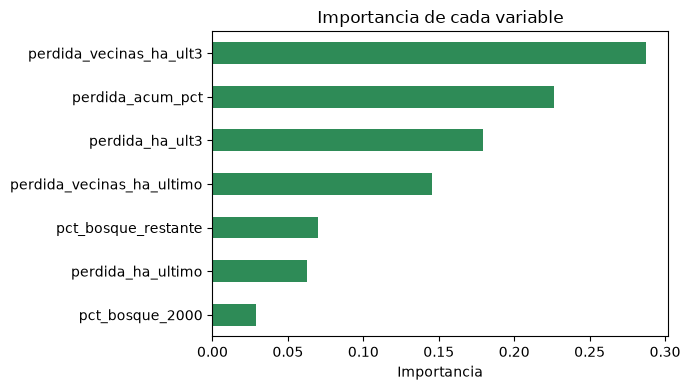

In [7]:
importancias = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
importancias.plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("Importancia de cada variable")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

## 7. Mapa de las 20 celdas más prioritarias

Tomamos el último año observado (2023) y predecimos 2024. En operación solo se conoce el riesgo; aquí, para evaluar el modelo, se pintan de **rojo** las celdas donde sí hubo pérdida y de **azul** las que no.

In [8]:
ultimo = test[test["anio_obs"] == test["anio_obs"].max()]
top = ultimo.nlargest(K, "riesgo")

dlat, dlon = meta_celdas["lado_lat"], meta_celdas["lado_lon"]
mapa = folium.Map(location=[top["lat"].mean(), top["lon"].mean()], zoom_start=10, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    name="Satélite",
).add_to(mapa)

for _, f in top.iterrows():
    color = "red" if f["alerta"] == 1 else "blue"
    folium.Rectangle(
        bounds=[[f["lat"] - dlat / 2, f["lon"] - dlon / 2], [f["lat"] + dlat / 2, f["lon"] + dlon / 2]],
        color=color,
        fill=True,
        fill_opacity=0.35,
        popup=f"Celda {int(f['celda_id'])}<br>Riesgo: {f['riesgo']:.2f}<br>Pérdida real: {f['perdida_ha_siguiente']:.1f} ha",
    ).add_to(mapa)

folium.LayerControl().add_to(mapa)

(RAIZ / "outputs").mkdir(exist_ok=True)
mapa.save(str(RAIZ / "outputs" / f"mapa_top{K}_{ZONA}.html"))
top[["celda_id", "lat", "lon", "riesgo", "perdida_ha_siguiente", "alerta"]].to_csv(
    RAIZ / "outputs" / f"top{K}_celdas_{ZONA}.csv", index=False
)
mapa

In [10]:
import sys

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.forestguard.model import entrenar_y_evaluar

res = entrenar_y_evaluar(panel, UMBRAL_HA)
res["resultados"].round(3)   # debe coincidir con la tabla de la sección 4

,conjunto,modelo,PR-AUC,precisión,recall
0,validación,Aleatorio,0.099,NaN,NaN
1,validación,Persistencia,0.442,0.492,0.548
2,validación,Random Forest,0.551,0.504,0.613
3,prueba,Aleatorio,0.064,NaN,NaN
4,prueba,Persistencia,0.256,0.331,0.383
5,prueba,Random Forest,0.331,0.354,0.420


## Hallazgos

- **Random Forest frente a las referencias:** supera a las dos en PR-AUC. En validación obtiene 0.551 frente a 0.442 de Persistencia (+0.109) y 0.099 del azar; en prueba, 0.331 frente a 0.256 (+0.075) y 0.064.
- **Variables más importantes:** la pérdida de las celdas vecinas en los últimos 3 años (`perdida_vecinas_ha_ult3`), seguida de la pérdida acumulada de la celda (`perdida_acum_pct`) y su pérdida en los últimos 3 años (`perdida_ha_ult3`). Es coherente con un frente de deforestación que avanza hacia las celdas contiguas.
- **Top-20:** en 2024, 12 de las 20 celdas priorizadas (60 %) tuvieron pérdida real, frente a 20 % de Persistencia y 8 % del azar. En 2023 fueron 10 de 20 (50 %), por debajo de Persistencia (65 %).
- **Otras zonas:** el modelo solo se validó en esta zona de Guaviare; no se puede asumir el mismo desempeño en otras regiones sin repetir la evaluación.